<a href="https://colab.research.google.com/github/AlbertP97/Med-VQA-Survey/blob/main/PathVQA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PathVQA Dataset Analysis

This notebook analyzes the PathVQA (Pathology Visual Question Answering) dataset for the doctoral research project (Paper 2).

## Dataset Overview
PathVQA is a dataset of medical visual question answering focusing on pathology images.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import word_tokenize

# Download necessary NLTK data
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Visualization configuration
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 2. Load and Explore the Data

In [2]:
from google.colab import files
import json

# Select and upload the file from the computer
uploaded_files = files.upload()

# Get the name of the uploaded file
file_name = next(iter(uploaded_files))

# Read the JSON file
json_data = json.loads(uploaded_files[file_name].decode('utf-8'))

# Convert it to a DataFrame
df = pd.DataFrame(json_data)

Saving PathVQA.json to PathVQA.json
Dataset loaded successfully
Number of records: 32795
Number of columns: 9


In [3]:
# Remove records with answer_type = 'number'
original_records = len(df)
df = df[df['answer_type'] != 'number'].copy()
filtered_records = len(df)
removed_records = original_records - filtered_records

print("Dataset loaded successfully")
print(f"Original records: {original_records}")
print(f"Records after removing answer_type='number': {filtered_records}")
print(f"Removed records: {removed_records}")
print(f"Number of columns: {len(df.columns)}")
print(f"\nFirst rows of the dataset:")
print(df.head())
print(f"\nDataset information:")
print(df.info())
print(f"\nDescriptive statistics:")
print(df.describe())

Dataset loaded successfully
Original records: 32795
Records after removing answer_type='number': 32694
Removed records: 101
Number of columns: 9

First rows of the dataset:
  answer_type  label question_type  \
0       other      0         where   
1       other      1          what   
2       other      2          what   
3      yes/no      3           are   
4       other      4          what   

                                            question  \
0   Where are liver stem cells (oval cells) located?   
1  What are stained here with an immunohistochemi...   
2  What are bile duct cells and canals of Hering ...   
3  Are bile duct cells and canals of Hering stain...   
4              What shows dissolution of the tissue?   

                                 answer        qid        image_name  \
0               in the canals of hering  100422000  train/train_0422   
1  bile duct cells and canals of hering  100422001  train/train_0422   
2          an immunohistochemical stain  1004

In [4]:
# Define list of allowed variables
variables = [
    'answer_type',
    'question_type',
    'question',
    'answer',
    'qid',
    'image_id',
    'phrase_type'
]

print("Allowed variables in PathVQA:")
for var in variables:
    print(f"  - {var}")

Allowed variables in PathVQA:
  - answer_type
  - question_type
  - question
  - answer
  - qid
  - image_id
  - phrase_type


In [5]:
# Calculate the length of questions and answers (in characters)
df['question_length'] = df['question'].str.len()
df['answer_length'] = df['answer'].str.len()

# Calculate length in words using NLTK
def count_words_nltk(text: str) -> int:
    """
    Count the words in a text using NLTK, excluding whitespace.

    Args:
        text: The text to analyze

    Returns:
        Number of words without whitespace
    """
    if not isinstance(text, str) or not text.strip():
        return 0
    tokens = word_tokenize(text.lower())
    # Filter tokens that are only whitespace or empty
    words = [token for token in tokens if token.strip()]
    return len(words)

df['question_words'] = df['question'].apply(count_words_nltk)
df['answer_words'] = df['answer'].apply(count_words_nltk)

print("Length columns created successfully")
print(f"  - question_length (characters)")
print(f"  - answer_length (characters)")
print(f"  - question_words (words - NLTK excluding whitespace)")
print(f"  - answer_words (words - NLTK excluding whitespace)")

Length columns created successfully
  - question_length (characters)
  - answer_length (characters)
  - question_words (words - NLTK excluding whitespace)
  - answer_words (words - NLTK excluding whitespace)


## 3. Exploratory Data Analysis

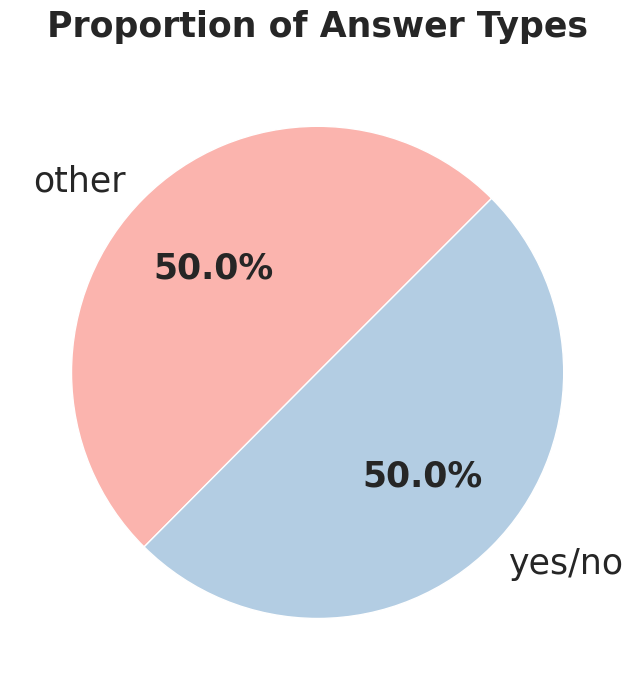

In [6]:
# ============================================================
# FIGURE 1: PROPORTION OF ANSWER TYPES
# PathVQA
# ============================================================

answer_types = df['answer_type'].value_counts()
colors_answer = plt.cm.Pastel1(range(len(answer_types)))

plt.figure(figsize=(9, 7))

wedges, texts, autotexts = plt.pie(
    answer_types.values,
    labels=answer_types.index,
    autopct='%1.1f%%',
    startangle=45,
    colors=colors_answer,
    textprops={'fontsize': 25}
)

for autotext in autotexts:
    autotext.set_fontweight('bold')

plt.title(
    'Proportion of Answer Types',
    fontsize=25,
    fontweight='bold',
    pad=20
)

plt.tight_layout()
plt.show()

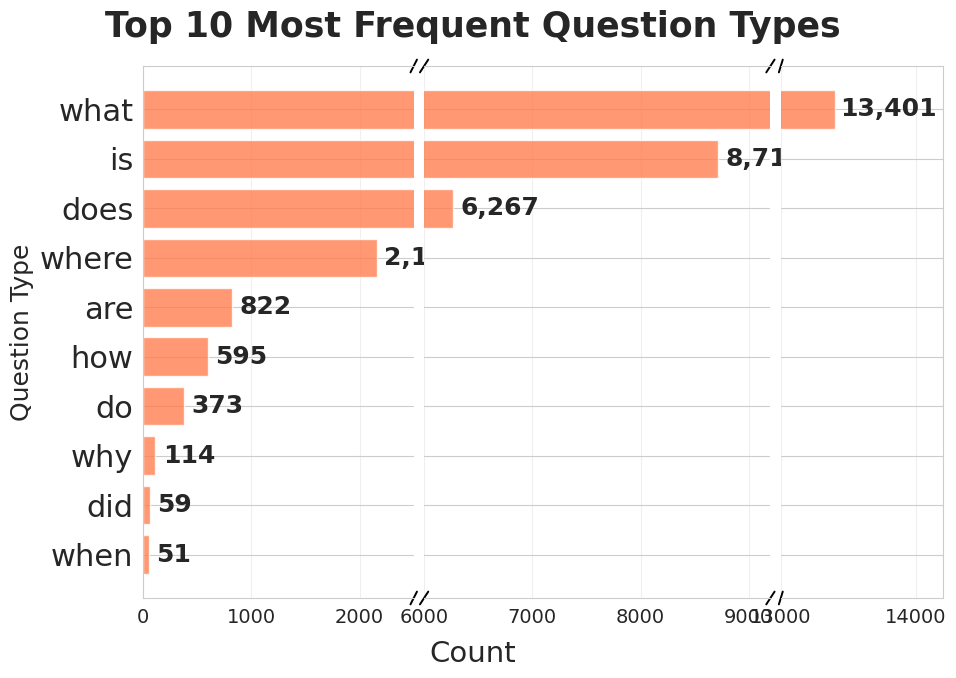

In [7]:
# ============================================================
# FIGURE 2: TOP 10 MOST FREQUENT
# QUESTION TYPES
# PathVQA
# ============================================================

question_types = (
    df['question_type']
    .value_counts()
    .head(10)
)

positions = np.arange(len(question_types))

# Three X-axis segments produce two breaks
fig, (ax1, ax2, ax3) = plt.subplots(
    1, 3,
    sharey=True,
    figsize=(10, 7),
    gridspec_kw={
        'width_ratios': [2.5, 3.2, 1.5],
        'wspace': 0.04
    }
)

axes = (ax1, ax2, ax3)

# Draw the same bars in the three segments
for ax in axes:
    ax.barh(
        positions,
        question_types.values,
        color='coral',
        alpha=0.8,
        height=0.78
    )

    ax.grid(
        axis='x',
        alpha=0.3
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis='x',
        labelsize=14
    )

# Limits of each segment
ax1.set_xlim(0, 2500)
ax2.set_xlim(6000, 9200)
ax3.set_xlim(13000, 14200)

# Y-axis labels
ax1.set_yticks(positions)
ax1.set_yticklabels(
    question_types.index,
    fontsize=22
)

ax1.set_ylabel(
    'Question Type',
    fontsize=18
)

# Hide repeated Y labels
ax2.tick_params(axis='y', left=False, labelleft=False)
ax3.tick_params(axis='y', left=False, labelleft=False)

# Show the most frequent value at the top
ax1.invert_yaxis()

# Hide interior borders
ax1.spines['right'].set_visible(False)

ax2.spines['left'].set_visible(False)
ax2.spines['right'].set_visible(False)

ax3.spines['left'].set_visible(False)

# Diagonal marks for the two breaks
d = 0.012

# Break between ax1 and ax2
kwargs = dict(
    color='black',
    clip_on=False,
    linewidth=1.4
)

ax1.plot(
    (1 - d, 1 + d),
    (-d, +d),
    transform=ax1.transAxes,
    **kwargs
)
ax1.plot(
    (1 - d, 1 + d),
    (1 - d, 1 + d),
    transform=ax1.transAxes,
    **kwargs
)

ax2.plot(
    (-d, +d),
    (-d, +d),
    transform=ax2.transAxes,
    **kwargs
)
ax2.plot(
    (-d, +d),
    (1 - d, 1 + d),
    transform=ax2.transAxes,
    **kwargs
)

# Break between ax2 and ax3
ax2.plot(
    (1 - d, 1 + d),
    (-d, +d),
    transform=ax2.transAxes,
    **kwargs
)
ax2.plot(
    (1 - d, 1 + d),
    (1 - d, 1 + d),
    transform=ax2.transAxes,
    **kwargs
)

ax3.plot(
    (-d, +d),
    (-d, +d),
    transform=ax3.transAxes,
    **kwargs
)
ax3.plot(
    (-d, +d),
    (1 - d, 1 + d),
    transform=ax3.transAxes,
    **kwargs
)

# Add each frequency in its corresponding segment
for position, value in zip(
    positions,
    question_types.values
):
    if value <= 2500:
        ax = ax1
        offset = 70
    elif value <= 9200:
        ax = ax2
        offset = 70
    else:
        ax = ax3
        offset = 40

    ax.text(
        value + offset,
        position,
        f'{value:,}',
        va='center',
        ha='left',
        fontsize=18,
        fontweight='bold'
    )

# Shared title and X label
fig.suptitle(
    'Top 10 Most Frequent Question Types',
    fontsize=25,
    fontweight='bold',
    y=0.98
)

fig.supxlabel(
    'Count',
    fontsize=21,
    y=0.04
)

plt.subplots_adjust(
    left=0.17,
    right=0.97,
    top=0.90,
    bottom=0.14
)

plt.show()

In [15]:
answer_type_norm = (
    df['answer_type']
    .astype(str)
    .str.strip()
    .str.lower()
)

phrase_type_norm = (
    df['phrase_type']
    .astype(str)
    .str.strip()
    .str.lower()
)

open_mask = (
    answer_type_norm.isin(['open', 'other']) |
    phrase_type_norm.eq('freeform')
)

answer_words_open = (
    df.loc[open_mask, 'answer_words']
    .dropna()
)

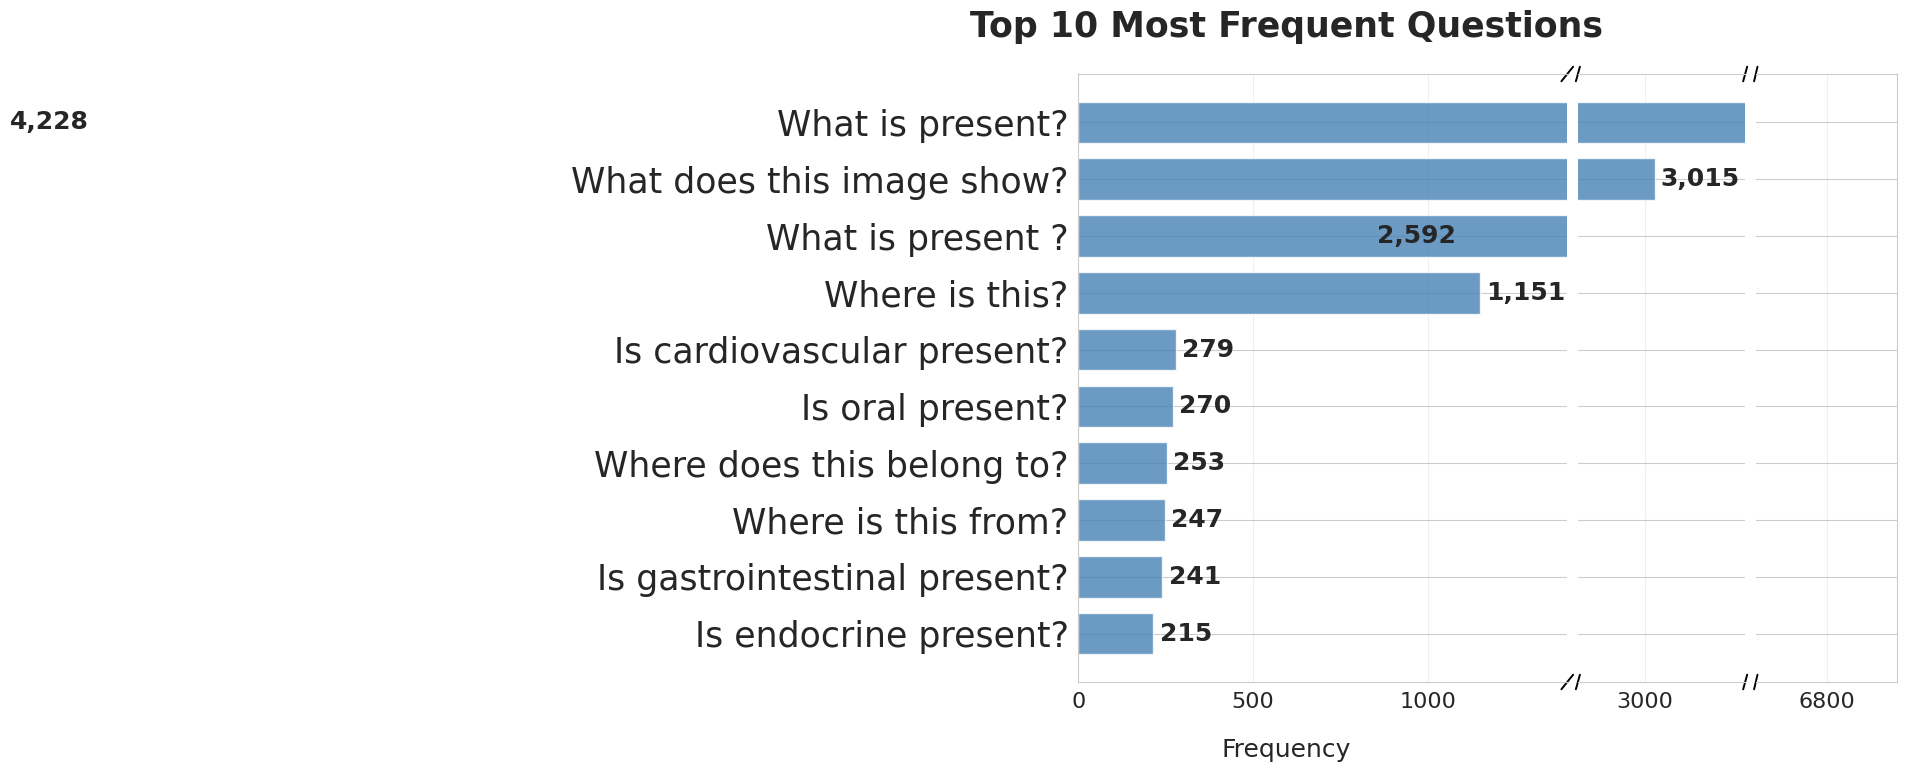

In [16]:
# ============================================================
# FIGURE 3: TOP 10 MOST FREQUENT QUESTIONS
# PathVQA
# ============================================================

# Compute the 10 most frequent questions
top_questions = (
    df['question']
    .value_counts()
    .head(10)
)

# Closer positions to each other
positions_y = np.arange(len(top_questions)) * 0.75

# Three X-axis segments to produce two breaks
fig, (ax1, ax2, ax3) = plt.subplots(
    1, 3,
    sharey=True,
    figsize=(13, 8),
    gridspec_kw={
        'width_ratios': [3.8, 1.3, 1.1],
        'wspace': 0.04
    }
)

axes = (ax1, ax2, ax3)

# Draw the bars in the three segments
for ax in axes:
    ax.barh(
        positions_y,
        top_questions.values,
        color='steelblue',
        alpha=0.8,
        height=0.55
    )

    ax.grid(
        axis='x',
        alpha=0.3
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis='x',
        labelsize=16
    )

# Limits of the three segments
ax1.set_xlim(0, 1400)
ax2.set_xlim(2900, 3150)
ax3.set_xlim(6700, 6900)

# X-axis ticks
ax1.set_xticks([0, 500, 1000])
ax2.set_xticks([3000])
ax3.set_xticks([6800])

# Question labels
ax1.set_yticks(positions_y)

ax1.set_yticklabels(
    top_questions.index,
    fontsize=25
)

# Hide repeated Y labels
ax2.tick_params(
    axis='y',
    left=False,
    labelleft=False
)

ax3.tick_params(
    axis='y',
    left=False,
    labelleft=False
)

# Show the most frequent question at the top
ax1.invert_yaxis()

# Hide interior borders
ax1.spines['right'].set_visible(False)

ax2.spines['left'].set_visible(False)
ax2.spines['right'].set_visible(False)

ax3.spines['left'].set_visible(False)

# Diagonal mark configuration
d = 0.012

kwargs = dict(
    color='black',
    clip_on=False,
    linewidth=1.4
)

# First break: ax1 and ax2
ax1.plot(
    (1 - d, 1 + d),
    (-d, +d),
    transform=ax1.transAxes,
    **kwargs
)

ax1.plot(
    (1 - d, 1 + d),
    (1 - d, 1 + d),
    transform=ax1.transAxes,
    **kwargs
)

ax2.plot(
    (-d, +d),
    (-d, +d),
    transform=ax2.transAxes,
    **kwargs
)

ax2.plot(
    (-d, +d),
    (1 - d, 1 + d),
    transform=ax2.transAxes,
    **kwargs
)

# Second break: ax2 and ax3
ax2.plot(
    (1 - d, 1 + d),
    (-d, +d),
    transform=ax2.transAxes,
    **kwargs
)

ax2.plot(
    (1 - d, 1 + d),
    (1 - d, 1 + d),
    transform=ax2.transAxes,
    **kwargs
)

ax3.plot(
    (-d, +d),
    (-d, +d),
    transform=ax3.transAxes,
    **kwargs
)

ax3.plot(
    (-d, +d),
    (1 - d, 1 + d),
    transform=ax3.transAxes,
    **kwargs
)

# Add the values at the end of the bars
for position, value in zip(
    positions_y,
    top_questions.values
):
    if value <= 1400:
        ax = ax1
        offset = 18

    elif value <= 3150:
        ax = ax2
        offset = 8

    else:
        ax = ax3
        offset = 5

    ax.text(
        value + offset,
        position,
        f'{value:,}',
        va='center',
        ha='left',
        fontsize=18,
        fontweight='bold'
    )

# Overall title
fig.suptitle(
    'Top 10 Most Frequent Questions',
    fontsize=25,
    fontweight='bold',
    y=0.98
)

# Shared X-axis label
fig.supxlabel(
    'Frequency',
    fontsize=18,
    y=0.04
)

plt.subplots_adjust(
    left=0.34,
    right=0.97,
    top=0.90,
    bottom=0.14
)

plt.show()

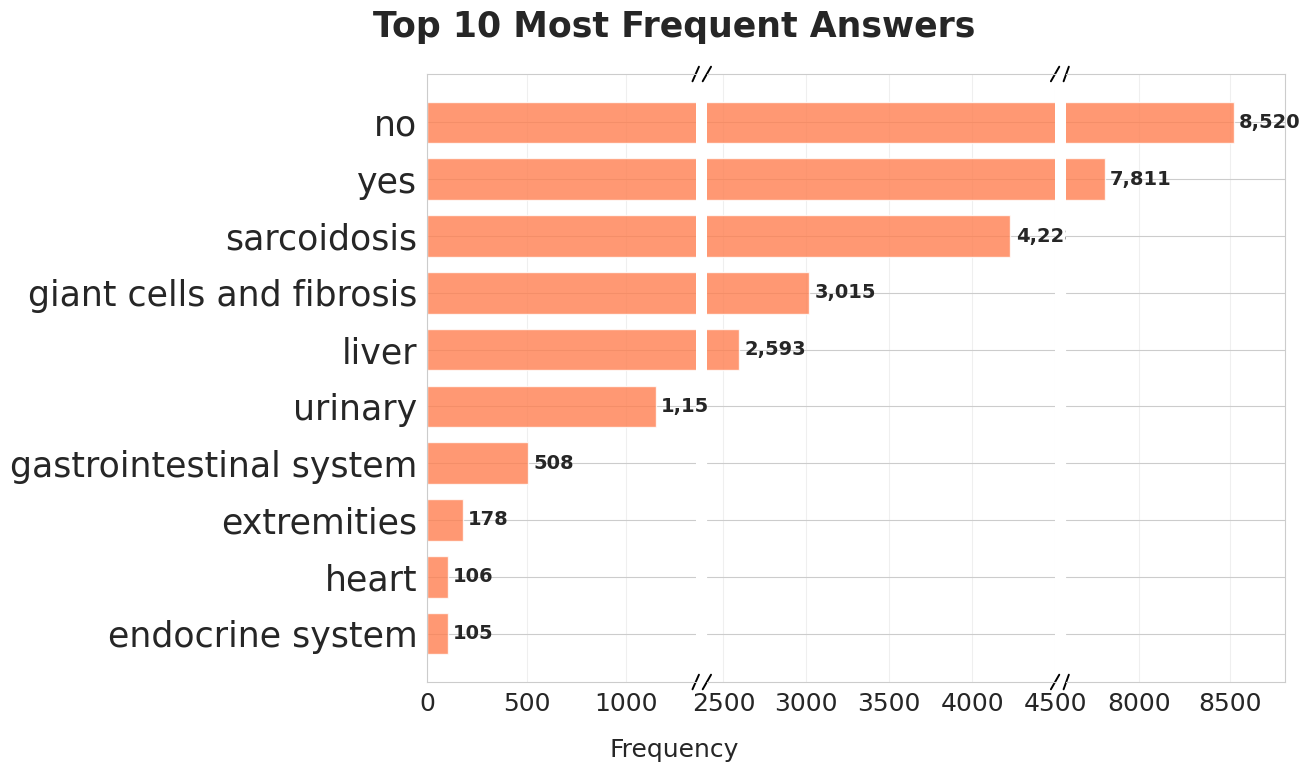

In [17]:
# ============================================================
# FIGURE 4: TOP 10 MOST FREQUENT ANSWERS
# PathVQA
# ============================================================

top_answers = (
    df['answer']
    .dropna()
    .astype(str)
    .str.strip()
    .value_counts()
    .head(10)
)

# Bar positions
positions_y = np.arange(len(top_answers)) * 0.75

# Three X-axis segments to generate two breaks
fig, (ax1, ax2, ax3) = plt.subplots(
    1, 3,
    sharey=True,
    figsize=(13, 8),
    gridspec_kw={
        'width_ratios': [2.7, 3.5, 2.2],
        'wspace': 0.04
    }
)

axes = (ax1, ax2, ax3)

# Draw the bars in each segment
for ax in axes:
    ax.barh(
        positions_y,
        top_answers.values,
        color='coral',
        alpha=0.8,
        height=0.55
    )

    ax.grid(
        axis='x',
        alpha=0.3
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis='x',
        labelsize=18
    )

# Limits of each segment
ax1.set_xlim(0, 1350)
ax2.set_xlim(2400, 4500)
ax3.set_xlim(7600, 8800)

# X-axis ticks
ax1.set_xticks([0, 500, 1000])
ax2.set_xticks([2500, 3000, 3500, 4000, 4500])
ax3.set_xticks([8000, 8500])

# Answer labels
ax1.set_yticks(positions_y)

ax1.set_yticklabels(
    top_answers.index,
    fontsize=25
)

# Hide repeated Y labels
ax2.tick_params(
    axis='y',
    left=False,
    labelleft=False
)

ax3.tick_params(
    axis='y',
    left=False,
    labelleft=False
)

# Show the most frequent answer at the top
ax1.invert_yaxis()

# Hide interior borders
ax1.spines['right'].set_visible(False)

ax2.spines['left'].set_visible(False)
ax2.spines['right'].set_visible(False)

ax3.spines['left'].set_visible(False)

# Size of the diagonal marks
d = 0.012

kwargs = dict(
    color='black',
    clip_on=False,
    linewidth=1.4
)

# First break: ax1 and ax2
ax1.plot(
    (1 - d, 1 + d),
    (-d, +d),
    transform=ax1.transAxes,
    **kwargs
)

ax1.plot(
    (1 - d, 1 + d),
    (1 - d, 1 + d),
    transform=ax1.transAxes,
    **kwargs
)

ax2.plot(
    (-d, +d),
    (-d, +d),
    transform=ax2.transAxes,
    **kwargs
)

ax2.plot(
    (-d, +d),
    (1 - d, 1 + d),
    transform=ax2.transAxes,
    **kwargs
)

# Second break: ax2 and ax3
ax2.plot(
    (1 - d, 1 + d),
    (-d, +d),
    transform=ax2.transAxes,
    **kwargs
)

ax2.plot(
    (1 - d, 1 + d),
    (1 - d, 1 + d),
    transform=ax2.transAxes,
    **kwargs
)

ax3.plot(
    (-d, +d),
    (-d, +d),
    transform=ax3.transAxes,
    **kwargs
)

ax3.plot(
    (-d, +d),
    (1 - d, 1 + d),
    transform=ax3.transAxes,
    **kwargs
)

# Show the values in the corresponding segment
for position, value in zip(
    positions_y,
    top_answers.values
):
    if value <= 1350:
        ax = ax1
        offset = 25

    elif value <= 4500:
        ax = ax2
        offset = 35

    else:
        ax = ax3
        offset = 25

    ax.text(
        value + offset,
        position,
        f'{value:,}',
        va='center',
        ha='left',
        fontsize=14,
        fontweight='bold'
    )

# Title
fig.suptitle(
    'Top 10 Most Frequent Answers',
    fontsize=25,
    fontweight='bold',
    y=0.98
)

# Shared X-axis label
fig.supxlabel(
    'Frequency',
    fontsize=18,
    y=0.04
)

plt.subplots_adjust(
    left=0.31,
    right=0.97,
    top=0.90,
    bottom=0.14
)

plt.show()

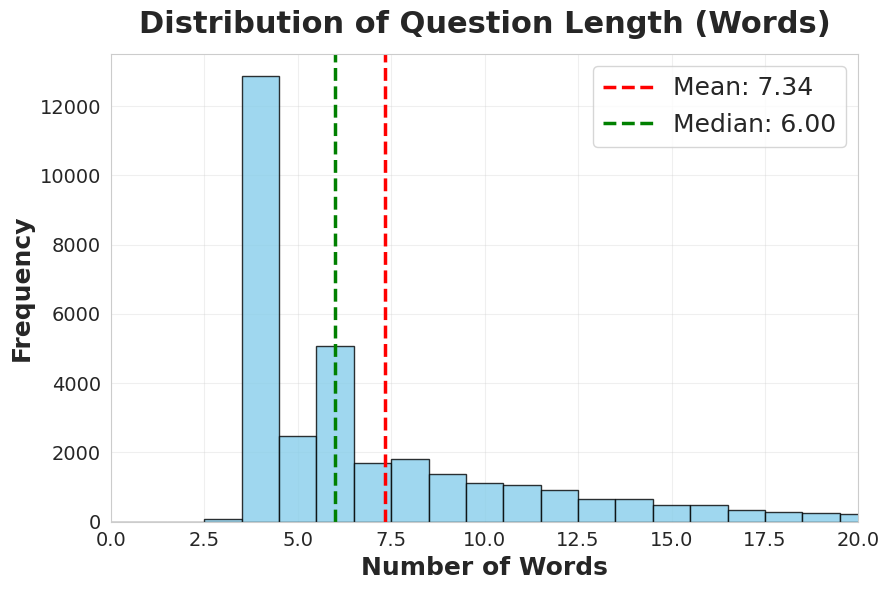

In [18]:
# ============================================================
# FIGURE 5: DISTRIBUTION OF QUESTION LENGTH
# PathVQA
# ============================================================

# Bins centered on each integer word count
max_question_words = int(df['question_words'].max())
bins_questions = np.arange(-0.5, max_question_words + 1.5, 1)

question_mean = df['question_words'].mean()
question_median = df['question_words'].median()

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df['question_words'],
    bins=bins_questions,
    color='skyblue',
    edgecolor='black',
    linewidth=1,
    alpha=0.8
)

ax.axvline(
    question_mean,
    color='red',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {question_mean:.2f}'
)

ax.axvline(
    question_median,
    color='green',
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {question_median:.2f}'
)

ax.set_xlim(0, 20)

ax.set_xlabel('Number of Words', fontsize=18, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=18, fontweight='bold')

ax.set_title(
    'Distribution of Question Length (Words)',
    fontsize=22,
    fontweight='bold',
    pad=15
)

ax.tick_params(axis='both', labelsize=14)
ax.legend(fontsize=18, loc='upper right')
ax.grid(alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

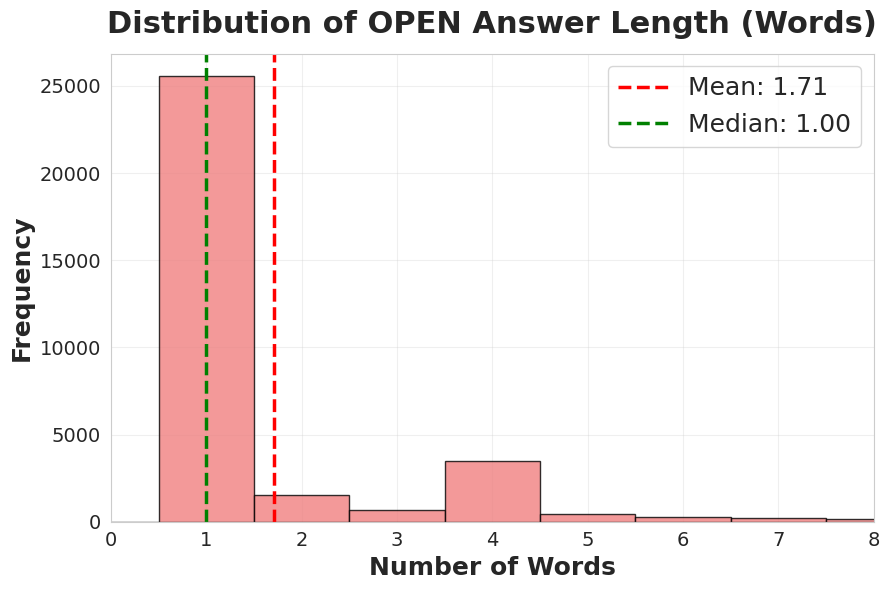

In [19]:
# ============================================================
# FIGURE 6: DISTRIBUTION OF ANSWER LENGTH
# PathVQA
# ============================================================

# Bins centered on each integer word count
max_answer_words = int(answer_words_open.max())
bins_answers = np.arange(-0.5, max_answer_words + 1.5, 1)

answer_mean = answer_words_open.mean()
answer_median = answer_words_open.median()

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    answer_words_open,
    bins=bins_answers,
    color='lightcoral',
    edgecolor='black',
    linewidth=1,
    alpha=0.8
)

ax.axvline(
    answer_mean,
    color='red',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {answer_mean:.2f}'
)

ax.axvline(
    answer_median,
    color='green',
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {answer_median:.2f}'
)

ax.set_xlim(0, 8)

ax.set_xlabel('Number of Words', fontsize=18, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=18, fontweight='bold')

ax.set_title(
    'Distribution of OPEN Answer Length (Words)',
    fontsize=22,
    fontweight='bold',
    pad=15
)

ax.tick_params(axis='both', labelsize=14)
ax.legend(fontsize=18, loc='upper right')
ax.grid(alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()